# Can Machine Learning Improve Stock-Sector Selection?

**CSCI E-278 — Applied Quantitative Finance and Machine Learning | Final project**

**Approved aim**

> The final aim is to see whether the machine-learning strategy adds value in unseen historical periods, and this is while recognising that past results cannot guarantee future returns.

**Did machine learning add value in unseen months?** Yes, compared with six-month momentum. From January 2022 through September 2026, the forest earned **8.07% a year** after trading costs and momentum earned **6.18%**. Holding SPY earned **11.94% a year**, so switching from SPY to the forest would have reduced the investor's return. The forest's 57-month record does not establish that it can beat momentum again. Section 12 explains how much uncertainty surrounds that comparison.

The universe consists of nine original Select Sector SPDR ETFs (XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV and XLY). SPY represents the broad market. The study covers January 2015 through September 2026. Prices from 2014 supply the history needed for the first signal.

Sections 1–5 cover the data and forecast timing. Sections 6–8 compare investment returns and prediction quality. Sections 9–12 examine costs, uncertainty and the conclusion. See the sources at the end.

## 1. Time and experiment design

| Period | Investment months | Use |
|:--|:--|:--|
| Initial training history | Jan 2015–Dec 2018 | Completed labels used to train the classifier |
| Walk-forward validation | Jan 2019–**Nov 2021** | Select among four pre-defined forest settings by Brier score |
| Freeze | Dec 2021 closing bell | Fix features, model settings, and benchmarks |
| Final unseen evaluation | Jan 2022–Sep 2026 | Compare investment outcomes without retuning |

**Why November 2021 is the last validation investment month.** December's *investment outcome* is only known at the first trading day's opening in January 2022. It was unavailable when deciding the January 2022 trade at the final December 2021 close. We therefore cannot use December 2021's realised outcome to choose hyperparameters.

The model produces a signal **after the last trading day's close** of a month. It buys at the **first market open of the next month**, holds until the **first open of the following month**, then rebalances. We train on a holding period only after its exit price is known. This excludes an unfinished position from the previous month. The expanding window grows as outcomes become available. The final-period model is refitted on past completed results, but settings remain locked.

The final September 2026 holding is valued using the first market opening in **October 2026**. No October observation is used to predict September's holdings.

## 2. Data and reproducibility

Daily Yahoo Finance **dividend- and split-adjusted Open and Close** are used. We download data from January 2014. `auto_adjust=True` is stated explicitly so a change in `yfinance` defaults cannot silently change our analysis. We use adjusted opening prices to calculate total returns. Actual execution prices can differ. We approximate trading costs with a fixed charge. The 13-week Treasury quote, `^IRX`, is an imperfect **risk-free-rate proxy**, rather than a tradable portfolio return.

This cell requires internet access on first execution. It writes a reproducible price snapshot to local `data/`. Rerunning with the same snapshot avoids market-vendor revisions. If downloading fails, execution stops: **we do not substitute synthetic returns**.

In [1]:
# Colab bootstrap. With a verified local price snapshot, no network is needed.
from pathlib import Path
import sys, subprocess
snapshot_files=['adjusted_open.csv','adjusted_close.csv','treasury_yield.csv','manifest.json']
if not all((Path('data')/p).is_file() for p in snapshot_files):
    try:
        import yfinance
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable,'-m','pip','install','-q','yfinance>=0.2.40'])


In [2]:
"""Original, time-aligned CSCI E-278 sector ETF experiment.

Research data must come from an actual Yahoo Finance snapshot. Test fixtures
are allowed in automated tests but must not be included in reported results.
"""
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss

SECTORS = ('XLB','XLE','XLF','XLI','XLK','XLP','XLU','XLV','XLY')
TICKERS = (*SECTORS,'SPY')
FEATURES = ('ret1','ret3','ret6','vol63','ma200_distance','relative3')
CANDIDATES = {
 'small_100':dict(n_estimators=100,max_depth=3,min_samples_leaf=20),
 'small_200':dict(n_estimators=200,max_depth=3,min_samples_leaf=20),
 'medium_100':dict(n_estimators=100,max_depth=5,min_samples_leaf=15),
 'medium_200':dict(n_estimators=200,max_depth=5,min_samples_leaf=15)
}
COST_BPS = 7.5
VALIDATION = ('2019-01','2021-11')
TEST = ('2022-01','2026-09')


def _extract(raw, field, tickers):
    if not isinstance(raw.columns,pd.MultiIndex):
        if len(tickers) != 1: raise ValueError('Multi-ticker Yahoo result not shaped as expected')
        out=raw[[field]].rename(columns={field:tickers[0]})
    elif field in raw.columns.get_level_values(0):
        out=raw.xs(field,axis=1,level=0)
    elif field in raw.columns.get_level_values(1):
        out=raw.xs(field,axis=1,level=1)
    else: raise ValueError('Missing OHLC field '+field)
    out=out.reindex(columns=list(tickers)).astype(float).sort_index()
    out.index=pd.DatetimeIndex(out.index).tz_localize(None).normalize()
    out.index.name='Date'
    return out


def load_prices(folder='data',refresh=False):
    """Use a saved snapshot when available and real vendor data for a fresh download."""
    d=Path(folder); d.mkdir(parents=True,exist_ok=True)
    paths=[d/'adjusted_open.csv',d/'adjusted_close.csv',d/'treasury_yield.csv']
    if all(p.exists() for p in paths) and not refresh:
        # Refuse silently altered snapshots rather than mixing vendor revisions.
        manifest_file=d/'manifest.json'
        if not manifest_file.exists():
            raise RuntimeError('Existing CSV snapshot lacks its SHA-256 manifest. Remove the incomplete snapshot and refresh the data.')
        saved=json.loads(manifest_file.read_text(encoding='utf-8'))
        for file in paths:
            expected=saved.get('sha256',{}).get(file.name)
            if not expected or hashlib.sha256(file.read_bytes()).hexdigest()!=expected:
                raise RuntimeError(f'Data snapshot integrity check failed for {file.name}')
        opened,closed=(pd.read_csv(p,index_col=0,parse_dates=True,float_precision='round_trip') for p in paths[:2])
        yield_pct=pd.read_csv(paths[2],index_col=0,parse_dates=True,float_precision='round_trip').iloc[:,0]
    else:
        import yfinance as yf
        raw=yf.download(list(TICKERS),start='2014-01-01',end='2026-10-10',
                        auto_adjust=True,interval='1d',progress=False,threads=False)
        if raw is None or raw.empty: raise RuntimeError('Yahoo ETF price download failed')
        opened=_extract(raw,'Open',TICKERS); closed=_extract(raw,'Close',TICKERS)
        y=yf.download('^IRX',start='2014-01-01',end='2026-10-10',
                      auto_adjust=False,interval='1d',progress=False,threads=False)
        if y is None or y.empty: raise RuntimeError('Yahoo 13-week yield download failed')
        yield_pct=_extract(y,'Close',('^IRX',)).iloc[:,0].rename('annual_yield_pct')
        validate_prices(opened,closed,yield_pct)
        opened.to_csv(paths[0]);closed.to_csv(paths[1]);yield_pct.to_frame().to_csv(paths[2])
        manifest={'source':'Yahoo Finance using yfinance','adjustment':'auto_adjust=True',
                  'download_start':'2014-01-01','download_end_exclusive':'2026-10-10',
                  'yfinance_version':getattr(yf,'__version__','unknown'),
                  'retrieved_utc':datetime.now(timezone.utc).isoformat(),
                  'tickers':list(TICKERS),'yield_proxy':'^IRX',
                  'sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}}
        (d/'manifest.json').write_text(json.dumps(manifest,indent=2))
    validate_prices(opened,closed,yield_pct)
    return opened,closed,yield_pct


def validate_prices(opened,closed,yields):
    for label,p in [('open',opened),('close',closed)]:
        assert set(TICKERS).issubset(p.columns),label+' missing ticker'
        assert p.index.is_unique and p.index.is_monotonic_increasing
        assert isinstance(p.index,pd.DatetimeIndex)
        assert (p.index.dayofweek<5).all(), label+' contains a weekend date'
        assert p.index.min() <= pd.Timestamp('2014-01-10')
        assert p.index.max() >= pd.Timestamp('2026-10-01')
        assert p.index.equals(opened.index),label+' date mismatch'
        assert p[list(TICKERS)].notna().all().all(),label+' incomplete data'
        assert (p[list(TICKERS)]>0).all().all()
        assert np.isfinite(p[list(TICKERS)].to_numpy()).all()
    assert yields.index.is_unique and yields.index.is_monotonic_increasing
    assert yields.dropna().between(-3,25).all(), 'Treasury yield units surprising'
    assert yields.loc[:'2026-09-30'].notna().any(), 'Missing risk-free-rate data'
    # Flag suspect outliers for inspection without assuming all crises are errors.
    jumps=closed[list(TICKERS)].pct_change().abs().max().max()
    assert jumps < 0.5, 'Price jump >50%. Inspect the corporate action adjustment.'


def make_panel(opened,closed,yields):
    """Month m uses signal at end of m-1 and exit at first opening of m+1."""
    validate_prices(opened,closed,yields)
    month_close=closed.groupby(closed.index.to_period('M')).last()
    month_last=closed.index.to_series().groupby(closed.index.to_period('M')).last()
    month_first=opened.index.to_series().groupby(opened.index.to_period('M')).first()
    changes={k:month_close.pct_change(k) for k in (1,3,6)}
    vol=closed.pct_change().rolling(63,min_periods=63).std()*np.sqrt(252)
    dist=closed/closed.rolling(200,min_periods=200).mean()-1
    rows=[]
    for month in pd.period_range('2015-01','2026-09',freq='M'):
        prev=month-1; nxt=month+1
        assert all(x in month_first.index for x in (month,nxt))
        signal=pd.Timestamp(month_last.loc[prev])
        entry=pd.Timestamp(month_first.loc[month]); exit_=pd.Timestamp(month_first.loc[nxt])
        assert signal<entry<exit_
        known=yields.loc[:signal].dropna()
        assert len(known) and (signal-known.index[-1]).days<=7
        month_rf=(1+float(known.iloc[-1])/100)**(1/12)-1
        spy_return=opened.at[exit_,'SPY']/opened.at[entry,'SPY']-1
        for ticker in SECTORS:
            prev_sector=changes[3].at[prev,ticker]
            prev_spy=changes[3].at[prev,'SPY']
            sector_ret=opened.at[exit_,ticker]/opened.at[entry,ticker]-1
            row=dict(month=str(month),ticker=ticker,signal_date=signal,entry_date=entry,
                     exit_date=exit_,label=int(sector_ret>spy_return),
                     realised=sector_ret,spy_return=spy_return,riskfree=month_rf,
                     ret1=changes[1].at[prev,ticker],ret3=prev_sector,
                     ret6=changes[6].at[prev,ticker],vol63=vol.at[signal,ticker],
                     ma200_distance=dist.at[signal,ticker],
                     relative3=(1+prev_sector)/(1+prev_spy)-1)
            rows.append(row)
    panel=pd.DataFrame(rows)
    assert panel.month.nunique()==141 and len(panel)==141*9
    assert np.isfinite(panel[list(FEATURES)].to_numpy()).all()
    assert panel[['ret1','ret3','ret6','vol63']].notna().all().all()
    assert (panel.vol63>0).all()
    assert panel.label.isin([0,1]).all()
    assert (panel.signal_date<panel.entry_date).all() and (panel.entry_date<panel.exit_date).all()
    assert panel.groupby('month').ticker.nunique().eq(9).all()
    return panel


def walkforward(panel,start,end,params,rolling_months=None):
    forecasts=[]; importances=[]
    for p in pd.period_range(start,end,freq='M'):
        current=panel[panel.month==str(p)].sort_values('ticker')
        assert len(current)==9
        signal=current.signal_date.iloc[0]
        train=panel[(panel.exit_date<=signal)&(panel.month<str(p))].copy()
        if rolling_months is not None:
            latest_complete = pd.Period(train.month.max(), freq='M')
            train = train[train.month >= str(latest_complete - rolling_months + 1)]
        assert len(train)>=216 and train.label.nunique()==2
        assert (train.exit_date<=signal).all(), 'Future label leaked into training!'
        forest=RandomForestClassifier(**params,max_features='sqrt',random_state=42,n_jobs=1)
        forest.fit(train[list(FEATURES)],train.label)
        positive=list(forest.classes_).index(1)
        prob=forest.predict_proba(current[list(FEATURES)])[:,positive]
        prior=float(train.label.mean())
        for (_,r),q in zip(current.iterrows(),prob):
            forecasts.append(dict(month=str(p),ticker=r.ticker,probability=float(q),
                                  reference_probability=prior,label=int(r.label),
                                  signal_date=signal,entry_date=r.entry_date,exit_date=r.exit_date,
                                  latest_training_exit=train.exit_date.max(),
                                  training_months=train.month.nunique()))
        importances.append(dict(month=str(p),**dict(zip(FEATURES,forest.feature_importances_))))
    out=pd.DataFrame(forecasts)
    assert out.groupby('month').ticker.nunique().eq(9).all()
    assert (out.latest_training_exit<=out.signal_date).all()
    return out,pd.DataFrame(importances)


def choose_model(panel):
    rows=[]
    for name,params in CANDIDATES.items():
        pred,_=walkforward(panel,*VALIDATION,params)
        rows.append(dict(name=name,brier=brier_score_loss(pred.label,pred.probability),
                         naive_brier=brier_score_loss(pred.label,pred.reference_probability)))
    table=pd.DataFrame(rows).sort_values(['brier','name']).reset_index(drop=True)
    name=table.iloc[0]['name']
    return name,CANDIDATES[name],table


def select(panel,pred,method):
    choices={}
    for month,pred_month in pred.groupby('month',sort=True):
        if method=='forest':
            ranked=pred_month.sort_values(['probability','ticker'],ascending=[False,True])
        elif method=='momentum':
            ranked=panel[panel.month==month].sort_values(['ret6','ticker'],ascending=[False,True])
        else: raise ValueError('Unknown selection rule')
        tickers=tuple(ranked.ticker.head(3))
        assert len(tickers)==len(set(tickers))==3
        choices[month]=tickers
    return choices


def simulate(panel,choices,bps=7.5,spy=False):
    """Monthly drift, then rebalance. Charge both buys and sells by dollar traded."""
    universe=('SPY',) if spy else SECTORS
    before=pd.Series(0.,index=universe)
    wealth=1.; rows=[]
    for month in sorted(choices):
        data=panel[panel.month==month]
        weights=pd.Series(0.,index=universe)
        if spy: weights['SPY']=1.
        else:
            assert len(choices[month])==3
            weights.loc[list(choices[month])]=1/3
        # Fees come out of the same account. Target weights apply to wealth
        # after fees. Solve fee = rate * sum(abs(target dollars - old dollars))
        # with all amounts expressed as fractions of pre-trade wealth.
        fee_rate = bps / 10000
        assert 0 <= fee_rate < 0.01
        cost = 0.0
        for _ in range(8):
            traded = float(((1 - cost) * weights - before).abs().sum())
            cost = fee_rate * traded
        assert abs(cost - fee_rate * float(((1 - cost) * weights - before).abs().sum())) < 1e-14
        rs=(pd.Series({'SPY':data.spy_return.iloc[0]}) if spy
            else data.set_index('ticker').realised.reindex(universe))
        gross=1+float(np.dot(weights,rs))
        assert gross>0 and cost<0.01
        net=(1-cost)*gross-1
        wealth*=1+net
        before=weights*(1+rs)/gross
        assert abs(before.sum()-1)<1e-10
        rows.append(dict(month=month,valuation_date=data.exit_date.iloc[0],
                         return_net=net,nav=wealth,turnover=traded,cost=cost,
                         riskfree=data.riskfree.iloc[0],selected=choices[month]))
    out=pd.DataFrame(rows).set_index('month')
    if spy:
        assert np.isclose(out.turnover.iloc[0] + out.cost.iloc[0], 1.)
        assert (out.turnover.iloc[1:]==0).all()
    return out


def metrics(result):
    r=result.return_net
    vol=float(r.std(ddof=1)*np.sqrt(12))
    excess=r-result.riskfree
    excess_vol=float(excess.std(ddof=1)*np.sqrt(12))
    nav=pd.concat([pd.Series([1.],index=['initial']),result.nav])
    dd=float((nav/nav.cummax()-1).min())
    return dict(CAGR=float(result.nav.iloc[-1]**(12/len(r))-1),
                volatility=vol,sharpe=float(excess.mean()*12/excess_vol) if excess_vol>0 else float('nan'),
                max_monthly_drawdown=dd,total_return=float(result.nav.iloc[-1]-1),
                annual_turnover=float(result.turnover.sum()*12/len(r)))


def forecast_diagnostics(pred):
    top=pred.sort_values(['month','probability','ticker'],ascending=[True,False,True]).groupby('month').head(3)
    stats={'brier':float(brier_score_loss(pred.label,pred.probability)),
           'naive_brier':float(brier_score_loss(pred.label,pred.reference_probability)),
           'classification_accuracy':float(((pred.probability>=.5)==pred.label).mean()),
           'top3_hit_rate':float(top.label.mean()),
           'random_top3_reference':float(pred.label.mean())}
    bins=pd.cut(pred.probability,np.linspace(0,1,6),include_lowest=True)
    reliability=pred.groupby(bins,observed=False).agg(n=('label','size'),
         mean_probability=('probability','mean'),observed_frequency=('label','mean'))
    return stats,reliability


def audit(panel,pred):
    assert pred.month.min()=='2022-01' and pred.month.max()=='2026-09'
    assert pred.month.nunique()==57 and len(pred)==513
    assert (pred.latest_training_exit<=pred.signal_date).all()
    assert (pred.signal_date<pred.entry_date).all()
    assert (pred.entry_date<pred.exit_date).all()
    dec=panel[panel.month=='2021-12'].iloc[0]
    jan=panel[panel.month=='2022-01'].iloc[0]
    assert dec.exit_date>jan.signal_date, 'December 2021 label must not tune Jan 2022 model'
    sep=panel[panel.month=='2026-09'].iloc[0]
    assert sep.exit_date.month==10 and sep.exit_date.year==2026
    return True


def block_bootstrap_ci(monthly_differences, block_months=6, draws=2000, seed=2026):
    """Circular block-bootstrap CI for a time-ordered monthly mean difference.

    We resample contiguous months, rather than individual ETF observations. This is
    an uncertainty diagnostic, rather than a formal guarantee of future performance.
    """
    x=np.asarray(monthly_differences,dtype=float)
    assert x.ndim==1 and len(x)>=24 and np.isfinite(x).all()
    assert 1<=block_months<=len(x) and 100<=draws<=10000
    rng=np.random.default_rng(seed)
    count=int(np.ceil(len(x)/block_months))
    starts=rng.integers(0,len(x),size=(draws,count))
    indices=((starts[:,:,None]+np.arange(block_months))%len(x)).reshape(draws,-1)[:,:len(x)]
    sampled_means=x[indices].mean(axis=1)
    low,high=np.quantile(sampled_means,[.025,.975])
    return {'mean_monthly_difference':float(x.mean()),
            'ci_low':float(low),'ci_high':float(high),
            'block_months':block_months,'draws':draws}


def top3_monthly_lift(pred):
    """Per-month uplift above same-month random sector selection baseline."""
    assert pred.groupby('month').ticker.nunique().eq(9).all()
    top=(pred.sort_values(['month','probability','ticker'],ascending=[True,False,True])
         .groupby('month',sort=True).head(3))
    best=top.groupby('month').label.mean()
    naive=pred.groupby('month').label.mean()
    assert best.index.equals(naive.index)
    return (best-naive).rename('top3_lift')


In [3]:
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn
print('pandas',pd.__version__,'scikit-learn',sklearn.__version__)
open_px, close_px, yield_pct = load_prices('data')
manifest=json.loads(Path('data/manifest.json').read_text(encoding='utf-8'))
print('Snapshot source:', manifest['source'], '| yfinance', manifest['yfinance_version'])
for filename, digest in manifest['sha256'].items():
    print(filename, digest)
print('Rows:',len(close_px),'available:',close_px.index.min().date(),'-',close_px.index.max().date())
display(close_px.loc[['2026-09-30']].round(2))
print('First October opening for the September exit:', open_px.loc['2026-10':].index[0].date())

pandas 3.0.5 scikit-learn 1.9.1
Snapshot source: Yahoo Finance using yfinance | yfinance 1.8.0
adjusted_open.csv e41a544f6973f4f3ea907fa5426b5ca523c6e009610a76f6b9bd786d05cdd58f
adjusted_close.csv 385d5a136ac6436e31a0f5d9c9c77794e90ef3d3a81349eeb256cb3daed65086
treasury_yield.csv 13ea64bee16618541762b3c9c17d0554600ca3eeb41c3e63960d424bdaa5add7
Rows: 3212 available: 2014-01-02 - 2026-10-09


,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,SPY
Date,,,,,,,,,,
2026-09-30,48.7,61.5,53.4,166.98,195.75,80.6,39.44,168.42,108.84,762.63


First October opening for the September exit: 2026-10-01


## 3. Six features and the prediction target

At the **prior month-end close**, we calculate each sector's returns over 1, 3 and 6 calendar months. The other three features are the annualised volatility of its last 63 daily returns, its distance from its 200-trading-day moving average and its 3-month return relative to SPY.

The label is **1** when the sector's upcoming first-open-to-first-open return exceeds SPY's over the same dates. Otherwise the label is **0**. This relative-performance label can be 1 even when the sector loses money. Each month contains nine related observations, rather than nine independent market regimes.

In [4]:
panel=make_panel(open_px,close_px,yield_pct)
print('Complete rows:',len(panel),'months:',panel.month.nunique())
assert len(panel)==1269 and panel.month.nunique()==141
assert np.isfinite(panel[list(FEATURES)].to_numpy()).all()
display(panel[['month','ticker','signal_date','entry_date','exit_date',*FEATURES,'label']].head(12))

Complete rows: 1269 months: 141


,month,ticker,signal_date,entry_date,exit_date,ret1,ret3,ret6,vol63,ma200_distance,relative3,label
0,2015-01,XLB,2014-12-31,2015-01-02,2015-02-02,-0.005569,-0.014192,-0.010618,0.191338,0.006816,-0.060242,1
1,2015-01,XLE,2014-12-31,2015-01-02,2015-02-02,-0.002108,-0.121035,-0.200184,0.287459,-0.123995,-0.162095,1
2,2015-01,XLF,2014-12-31,2015-01-02,2015-02-02,0.018702,0.072781,0.097584,0.146666,0.085231,0.022668,0
3,2015-01,XLI,2014-12-31,2015-01-02,2015-02-02,-0.000216,0.070512,0.057456,0.169080,0.059768,0.020505,0
4,2015-01,XLK,2014-12-31,2015-01-02,2015-02-02,-0.021767,0.041732,0.088500,0.153566,0.071624,-0.006931,0
5,2015-01,XLP,2014-12-31,2015-01-02,2015-02-02,-0.009357,0.082658,0.101480,0.114364,0.083178,0.032083,1
6,2015-01,XLU,2014-12-31,2015-01-02,2015-02-02,0.035672,0.131882,0.086089,0.160710,0.109657,0.079008,1
7,2015-01,XLV,2014-12-31,2015-01-02,2015-02-02,-0.014034,0.073902,0.132298,0.181521,0.100051,0.023737,1
8,2015-01,XLY,2014-12-31,2015-01-02,2015-02-02,0.008900,0.086356,0.089173,0.144849,0.085628,0.035609,0
9,2015-02,XLB,2015-01-30,2015-02-02,2015-03-02,-0.018320,-0.008458,-0.008979,0.182904,-0.014966,-0.002974,1


## 4. Walk-forward model selection: prediction quality first

We compare four forests. Each has 100 or 200 trees. The shallower trees have a maximum depth of 3 and at least 20 observations per leaf. The deeper trees have a maximum depth of 5 and at least 15 observations per leaf. Their settings were fixed before looking at final test outcomes. For each month in the 2019–November 2021 validation period, we train only on labels whose outcomes are already known, then forecast the nine sectors.

The **Brier score** evaluates probability quality: lower is better. We compare it with a no-lookahead forecast that simply uses the historical frequency of positive labels. A four-year rolling training window is reported as a robustness check alongside our primary **expanding window**, but it is **not** selected based on the unseen 2022–2026 returns. A fixed random seed makes fitting reproducible.

In [5]:
name,chosen_params,validation_table=choose_model(panel)
print('Locked model:',name,chosen_params)
display(validation_table.round(4))
valid_forecasts,_=walkforward(panel,*VALIDATION,chosen_params)
rolling_forecasts,_=walkforward(panel,*VALIDATION,chosen_params,rolling_months=48)
window_results=pd.DataFrame({'training_window':['Expanding','Rolling 48 months'],
    'validation_Brier':[brier_score_loss(valid_forecasts.label,valid_forecasts.probability),
                        brier_score_loss(rolling_forecasts.label,rolling_forecasts.probability)]})
display(window_results.round(4))
assert valid_forecasts.month.max()=='2021-11'
assert rolling_forecasts.training_months.max()==48
print('Lowest validation Brier among the four forests:', round(validation_table.brier.min(),4))
print('Historical-frequency benchmark:', round(validation_table.naive_brier.iloc[0],4))

Locked model: small_100 {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 20}


,name,brier,naive_brier
0,small_100,0.2542,0.2488
1,small_200,0.2543,0.2488
2,medium_200,0.2569,0.2488
3,medium_100,0.2573,0.2488


,training_window,validation_Brier
0,Expanding,0.2542
1,Rolling 48 months,0.2566


Lowest validation Brier among the four forests: 0.2542
Historical-frequency benchmark: 0.2488


All four forests produced larger validation errors than the historical-frequency benchmark. The shallow, 100-tree model was the best of the four. The original model-selection rule carried that forest into the final test.

## 5. Lock the model and predict January 2022–September 2026

No hyperparameters, features or investment rules may be changed using the final results. For every forecast, the calendar audit verifies that the latest training label completed **before the forecast signal**. A January 2022 signal therefore cannot train on the December 2021 position's unrealised return.

In [6]:
final_forecasts,feature_importance=walkforward(panel,*TEST,chosen_params)
assert audit(panel,final_forecasts)
print('PASS: 57 final monthly forecasts, 513 sector-level predictions. All training labels were known at the signal date.')
display(final_forecasts.head(9))

PASS: 57 final monthly forecasts, 513 sector-level predictions. All training labels were known at the signal date.


,month,ticker,probability,reference_probability,label,signal_date,entry_date,exit_date,latest_training_exit,training_months
0,2022-01,XLB,0.436673,0.472557,0,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
1,2022-01,XLE,0.469738,0.472557,1,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
2,2022-01,XLF,0.400985,0.472557,1,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
3,2022-01,XLI,0.385013,0.472557,1,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
4,2022-01,XLK,0.536742,0.472557,0,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
5,2022-01,XLP,0.480179,0.472557,1,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
6,2022-01,XLU,0.431579,0.472557,1,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
7,2022-01,XLV,0.425333,0.472557,0,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83
8,2022-01,XLY,0.493890,0.472557,0,2021-12-31,2022-01-03,2022-02-01,2021-12-01,83


## 6. Three investment strategies and transaction costs

**Forest:** buy the three sectors with the highest predicted probabilities, even if all are below 50%.

**Momentum:** buy the three sectors with the highest **prior six-month** adjusted close-to-close returns.

**SPY:** invest once and hold. No subsequent trading.

Sector strategies target **one-third in each selected ETF** at each monthly opening. Weights drift as sector prices change. Each month the strategy pays fees from its own capital, then invests what remains at the target weights. Holding the same names can still require trades. We charge **7.5 basis points (0.075%) on the dollar value bought *and* sold**, including the initial purchases. The final observation marks the open positions to market. The simulation charges no terminal sale. Turnover includes purchases and sales, each measured against wealth immediately before the trade. We separately test 0, 5, 10 and 20 basis points.

In [7]:
forest_picks=select(panel,final_forecasts,'forest')
momentum_picks=select(panel,final_forecasts,'momentum')
spy_picks={mo:('SPY',) for mo in forest_picks}
strategies={
 'Random forest':simulate(panel,forest_picks,bps=COST_BPS),
 'Six-month momentum':simulate(panel,momentum_picks,bps=COST_BPS),
 'SPY buy-and-hold':simulate(panel,spy_picks,bps=COST_BPS,spy=True)
}
assert all(len(x)==57 for x in strategies.values())
assert all(x.index.equals(strategies['Random forest'].index) for x in strategies.values())
print('PASS: identical 57-month investment horizons, cost and drift accounting')
display(pd.DataFrame({'Forest':pd.Series(forest_picks),'Momentum':pd.Series(momentum_picks)}).head(12))

PASS: identical 57-month investment horizons, cost and drift accounting


,Forest,Momentum
2022-01,"(XLK, XLY, XLP)","(XLK, XLU, XLY)"
2022-02,"(XLV, XLI, XLB)","(XLE, XLF, XLP)"
2022-03,"(XLB, XLY, XLF)","(XLE, XLP, XLF)"
2022-04,"(XLY, XLE, XLF)","(XLE, XLU, XLB)"
2022-05,"(XLI, XLV, XLB)","(XLE, XLP, XLU)"
2022-06,"(XLE, XLP, XLF)","(XLE, XLU, XLP)"
2022-07,"(XLP, XLV, XLU)","(XLE, XLU, XLP)"
2022-08,"(XLI, XLV, XLK)","(XLE, XLU, XLV)"
2022-09,"(XLP, XLI, XLV)","(XLE, XLU, XLP)"
2022-10,"(XLE, XLP, XLF)","(XLE, XLU, XLP)"


## 7. Performance and downside risk

CAGR is the annual compound growth rate. Annual volatility equals the standard deviation of monthly portfolio returns times the square root of 12. For the Sharpe ratio, subtract the monthly Treasury proxy from each portfolio return, divide the mean of these excess returns by their standard deviation, and multiply by the square root of 12. The Treasury proxy converts the quoted annual yield at the signal date to a monthly effective rate. Maximum drawdown measures the largest decline from an earlier peak at the monthly valuations.

Dollar charts show the growth of a **$10,000** initial investment, after the assumed costs. The chart includes initial capital at the first entry opening, ensuring that first-month losses count towards the drawdown.

,Annual return,Annual volatility,Sharpe,Maximum drawdown,Total return,Annual turnover (x)
Random forest,8.07%,15.62%,0.332,-26.52%,44.55%,12.69
Six-month momentum,6.18%,14.89%,0.220,-12.20%,32.93%,8.09
SPY buy-and-hold,11.94%,15.25%,0.572,-23.37%,70.85%,0.21


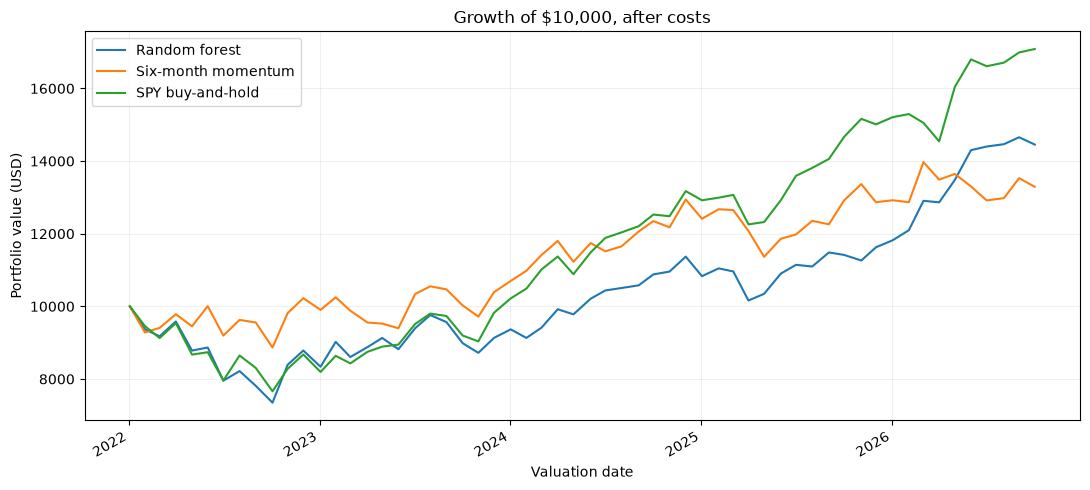

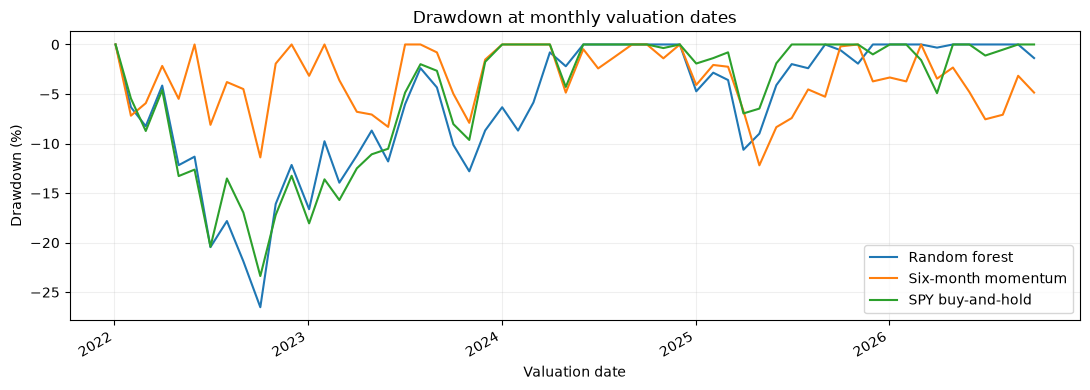

In [8]:
performance=pd.DataFrame({k:metrics(v) for k,v in strategies.items()}).T
performance_table = performance.rename(columns={
    'CAGR': 'Annual return', 'volatility': 'Annual volatility', 'sharpe': 'Sharpe',
    'max_monthly_drawdown': 'Maximum drawdown', 'total_return': 'Total return',
    'annual_turnover': 'Annual turnover (x)'})
display(performance_table.style.format({
    'Annual return':'{:.2%}', 'Annual volatility':'{:.2%}', 'Sharpe':'{:.3f}',
    'Maximum drawdown':'{:.2%}', 'Total return':'{:.2%}', 'Annual turnover (x)':'{:.2f}'}))
values=pd.DataFrame({k:v.nav.to_numpy()*10000 for k,v in strategies.items()},
                    index=strategies['Random forest'].valuation_date)
values.index.name='Valuation date'
first_open=panel.loc[panel.month=='2022-01','entry_date'].iloc[0]
values=pd.concat([pd.DataFrame({k:[10000.] for k in values.columns},
                               index=pd.DatetimeIndex([first_open],name='Valuation date')),values])
assert np.allclose(values.iloc[0].to_numpy(),10000)
ax=values.plot(figsize=(11,5),title='Growth of $10,000, after costs')
ax.set_ylabel('Portfolio value (USD)');ax.grid(alpha=.2);plt.tight_layout();plt.show()
drawdowns=values.div(values.cummax()).sub(1)*100
assert all(np.isclose(drawdowns[k].min()/100,performance.loc[k,'max_monthly_drawdown'])
           for k in values.columns), 'Drawdown chart differs from risk table'
ax=drawdowns.plot(figsize=(11,4),title='Drawdown at monthly valuation dates')
ax.set_ylabel('Drawdown (%)');ax.grid(alpha=.2);plt.tight_layout();plt.show()

SPY finished with the most wealth and the highest Sharpe ratio. Momentum had the shallowest drawdown. The forest lost about a quarter of its value from its peak and traded about 12.7 dollars per year for each dollar invested, counting buys and sells. SPY turnover consists of the initial purchase spread over the full test period.

## 8. Does the forest actually predict better?

The Brier score measures the accuracy of the predicted probabilities, rather than portfolio profits or the quality of the sector rankings. We also report the **top-three hit rate** (share of selected sector-months that outperform SPY), compare it with the expected rate of choosing three of the nine sectors at random, and inspect **calibration** in five probability bins. The random baseline is a *diagnostic*, rather than an investable trading strategy.

,brier,naive_brier,classification_accuracy,top3_hit_rate,random_top3_reference,brier_skill_vs_historical_frequency
Final test,0.2502,0.2494,0.5322,0.462,0.4659,-0.0031


,n,mean_probability,observed_frequency
probability,,,
"(-0.001, 0.2]",0,NaN,NaN
"(0.2, 0.4]",2,0.386,1.000
"(0.4, 0.6]",509,0.483,0.464
"(0.6, 0.8]",2,0.605,0.500
"(0.8, 1.0]",0,NaN,NaN


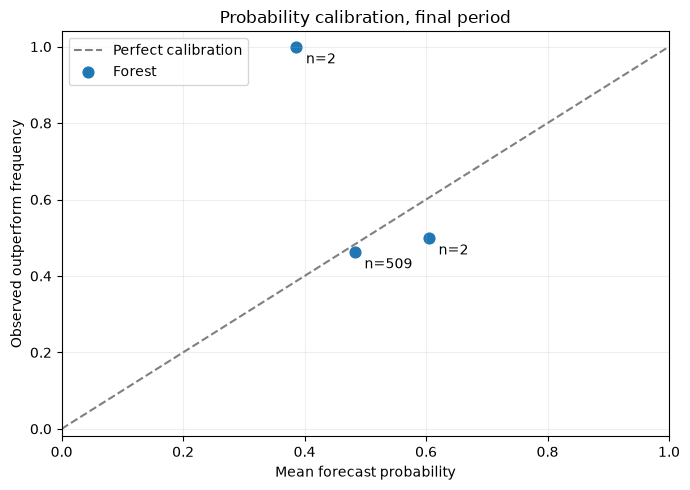

In [9]:
quality,calibration=forecast_diagnostics(final_forecasts)
quality['brier_skill_vs_historical_frequency']=1-quality['brier']/quality['naive_brier']
display(pd.DataFrame([quality],index=['Final test']).round(4))
display(calibration.round(3))
valid_bins=calibration.dropna(subset=['mean_probability','observed_frequency'])
fig,ax=plt.subplots(figsize=(7,5))
ax.plot([0,1],[0,1],ls='--',color='grey',label='Perfect calibration')
ax.scatter(valid_bins.mean_probability,valid_bins.observed_frequency,s=60,label='Forest')
for row in valid_bins.itertuples():
    ax.annotate(f'n={row.n}', (row.mean_probability,row.observed_frequency),
                xytext=(7,-12), textcoords='offset points')
ax.set(xlim=(0,1),ylim=(-.02,1.04),xlabel='Mean forecast probability',
       ylabel='Observed outperform frequency',title='Probability calibration, final period')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

Of 513 forecasts, 509 fell in the 40–60% bin. Their average predicted probability was 48.3%, and sectors beat SPY in 46.4% of those cases. Each of the two other occupied bins contained just two observations. The plot provides little information about calibration at those extremes.

## 9. Cost sensitivity and stability

Here we keep the actual selections unchanged and calculate portfolio outcomes at five costs. We do **not** choose the cost with the best result. Feature-importance values average the sequentially fitted final-period forests. Correlated features may share importance. These scores describe how the trees made splits. They do not establish causation.

strategy,Random forest,SPY buy-and-hold,Six-month momentum
one_way_cost_bps,,,
0.000000,9.10%,11.95%,6.82%
5.000000,8.41%,11.94%,6.39%
7.500000,8.07%,11.94%,6.18%
10.000000,7.72%,11.93%,5.96%
20.000000,6.36%,11.91%,5.11%


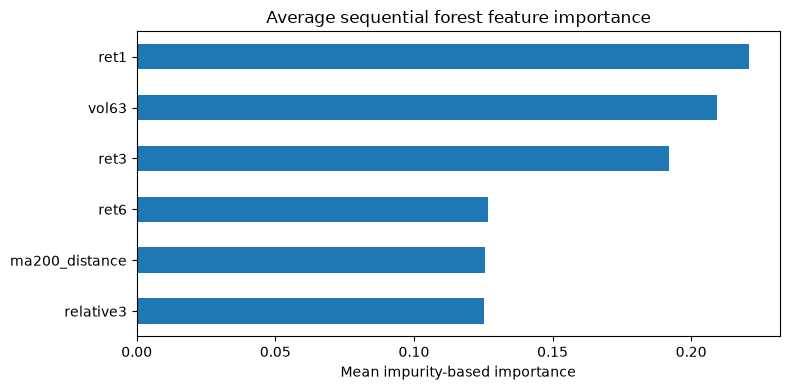

In [10]:
grid=[]
for bps in [0,5,7.5,10,20]:
    for name,picks,is_spy in [('Random forest',forest_picks,False),
                              ('Six-month momentum',momentum_picks,False),
                              ('SPY buy-and-hold',spy_picks,True)]:
        res=metrics(simulate(panel,picks,bps=bps,spy=is_spy))
        grid.append({'one_way_cost_bps':bps,'strategy':name,**res})
cost_table=pd.DataFrame(grid)
display(cost_table.pivot(index='one_way_cost_bps',columns='strategy',values='CAGR').style.format('{:.2%}'))
ax=feature_importance[list(FEATURES)].mean().sort_values().plot.barh(figsize=(8,4),
      title='Average sequential forest feature importance')
ax.set_xlabel('Mean impurity-based importance');plt.tight_layout();plt.show()

SPY led at every tested cost, even with free trading. The forest beat momentum at all five rates. Trading costs reduced the forest's return most because it traded the most. The forest assigned the greatest average importance to one-month return and 63-day volatility. Their high rank describes how the trees split observations and says little about forecast accuracy on its own.

## 10. How uncertain are the differences?

The 57 investment months are not independent observations. We therefore use a **six-month circular block bootstrap** to estimate approximate 95% intervals for the difference in mean monthly returns between the forest and each benchmark. We also bootstrap the month-level top-three hit-rate advantage over a random three-sector selection. Each resample preserves contiguous groups of months and the cross-sector outcomes within each month. We never use the resulting intervals to redesign the model.

The table reports percentage-point differences per month. Return differences use the arithmetic mean of paired monthly net returns. The hit-rate difference compares the selected three with the fraction of all nine sectors beating SPY that month. These units differ from the annual compound returns above.

In [11]:
lift_by_month=top3_monthly_lift(final_forecasts)
bootstrap_tests={
 'Forest minus momentum return':block_bootstrap_ci(
      strategies['Random forest'].return_net.to_numpy()-
      strategies['Six-month momentum'].return_net.to_numpy()),
 'Forest minus SPY return':block_bootstrap_ci(
      strategies['Random forest'].return_net.to_numpy()-
      strategies['SPY buy-and-hold'].return_net.to_numpy()),
 'Top-three hit-rate lift vs random':block_bootstrap_ci(lift_by_month.to_numpy())
}
uncertainty=pd.DataFrame(bootstrap_tests).T
intervals_pp = 100 * uncertainty[['mean_monthly_difference','ci_low','ci_high']]
intervals_pp.columns = ['Mean (pp)', 'Lower 95% (pp)', 'Upper 95% (pp)']
display(intervals_pp.round(2))
print('Approximate 95% intervals from 2,000 draws of six-month blocks.')

,Mean (pp),Lower 95% (pp),Upper 95% (pp)
Forest minus momentum return,0.16,-0.74,1.11
Forest minus SPY return,-0.29,-0.90,0.38
Top-three hit-rate lift vs random,-0.39,-5.26,4.09


Approximate 95% intervals from 2,000 draws of six-month blocks.


## 11. Changing market conditions and what the findings mean

We examine each year's realised performance to avoid overlooking a strategy that only works in one kind of market. This analysis is **descriptive**: after seeing these values we do not change the test set or any model setting.

Interpret the investment results alongside prediction quality and turnover. A model can forecast relative performance reasonably well and still fail to earn more than SPY. Conversely, higher realised return over a short sample need not mean the model learned a persistent signal.

In [12]:
monthly=pd.DataFrame({name:out.return_net.to_numpy() for name,out in strategies.items()},
    index=pd.PeriodIndex(strategies['Random forest'].index,freq='M'))
annual=monthly.groupby(monthly.index.year).agg(lambda x:(1+x).prod()-1)
display(annual.rename_axis('Investment year').style.format('{:.2%}'))
print('The 2026 entry covers only the nine months from January through September.')
fr=performance.loc['Random forest','CAGR']; mo=performance.loc['Six-month momentum','CAGR']
spy=performance.loc['SPY buy-and-hold','CAGR']
forest_before_2026 = (1 + monthly.loc[:'2025-12', 'Random forest']).prod() - 1
momentum_before_2026 = (1 + monthly.loc[:'2025-12', 'Six-month momentum']).prod() - 1
conclusion = f"""**Was the forest worth using?** Over the full test it earned **{fr:.2%}** a year after costs. Momentum earned **{mo:.2%}** and SPY earned **{spy:.2%}**. The timing matters. Through December 2025 the forest had gained **{forest_before_2026:.1%}**, while momentum had gained **{momentum_before_2026:.1%}**. The forest overtook momentum in the final nine months, when it earned **{annual.loc[2026, 'Random forest']:.1%}**.

**Could it pick winners?** The three selected sectors beat SPY in **{quality['top3_hit_rate']:.1%}** of cases. Random selection would have averaged **{quality['random_top3_reference']:.1%}** across the same months. The Brier score was **{quality['brier']:.4f}**, slightly worse than the historical-frequency forecast of **{quality['naive_brier']:.4f}**. A sector can miss SPY by a small amount or beat it by a large one. The hit rate counts both events equally, while portfolio returns depend on the size of each gain or loss.

**How much confidence is warranted?** All three block-bootstrap intervals include zero. This sample gives little evidence of a repeatable sector-selection advantage. The difference in realised wealth is meaningful to an investor who lived through this period, but 57 monthly decisions provide limited evidence about the next period."""
display(Markdown(conclusion))

,Random forest,Six-month momentum,SPY buy-and-hold
Investment year,,,
2022,-16.62%,-0.98%,-18.05%
2023,12.34%,8.05%,24.71%
2024,15.64%,16.01%,26.43%
2025,9.12%,4.10%,17.71%
2026,22.29%,2.88%,12.34%


The 2026 entry covers only the nine months from January through September.


**Was the forest worth using?** Over the full test it earned **8.07%** a year after costs. Momentum earned **6.18%** and SPY earned **11.94%**. The timing matters. Through December 2025 the forest had gained **18.2%**, while momentum had gained **29.2%**. The forest overtook momentum in the final nine months, when it earned **22.3%**.

**Could it pick winners?** The three selected sectors beat SPY in **46.2%** of cases. Random selection would have averaged **46.6%** across the same months. The Brier score was **0.2502**, slightly worse than the historical-frequency forecast of **0.2494**. A sector can miss SPY by a small amount or beat it by a large one. The hit rate counts both events equally, while portfolio returns depend on the size of each gain or loss.

**How much confidence is warranted?** All three block-bootstrap intervals include zero. This sample gives little evidence of a repeatable sector-selection advantage. The difference in realised wealth is meaningful to an investor who lived through this period, but 57 monthly decisions provide limited evidence about the next period.

## 12. Conclusion against the approved aim

For a $10,000 initial investment, the ending values in dollars were **14,455** for the forest, **13,293** for momentum and **17,085** for SPY. The extra return over momentum came with a deeper peak-to-trough loss (**26.52%** versus **12.20%** at monthly valuations).

**Would the lead over momentum carry over to another period?** The forest earned **0.16 percentage points more per month** than momentum on average. The approximate 95% interval for that difference runs from **0.74 points behind** momentum to **1.11 points ahead**. Zero falls inside that range, so an average advantage of zero is also consistent with the data. The forest beat momentum over these particular 57 months. We cannot conclude from this test that its sector picks will beat momentum in another period. **Past results cannot guarantee future returns.**

### Limits of the comparison

Our nine fixed ETFs do not cover the modern full eleven-sector SPDR universe. Historical GICS classification changes affect comparisons. ETFs remain diversified and liquid, but first-open prices need not match an actual order's fill. Dividend-adjusted prices approximate reinvestment. We do not estimate spreads, taxes, market impact or commissions separately. The 7.5-bps transaction cost is only an assumption, tested at alternatives. The `^IRX` quoted yield is an approximation to a risk-free monthly rate. Drawdowns sampled monthly understate some intramonth pain. Market conditions, selected thresholds and the relatively small number of independent months limit confidence. The project tests whether the strategy added value during the historical test period.

**Reproduce and validate.** Run every notebook cell in order, retain the downloaded `data` snapshot and its SHA-256 manifest, and run the accompanying `pytest` tests. Examine errors and any outliers rather than silently deleting dates. Do not interpret charts until the data and timing assertions pass. The unit tests use synthetic fixtures to test code behaviour, rather than to generate the reported investment results.

**Sources.** Course sources include the CSCI E-278 Fall 2026 syllabus, the notes for Modules I–IV and lecture notebooks on walk-forward testing, random forests and portfolio risk. We also used Yahoo Finance historical data, the `yfinance` price-adjustment documentation and the scikit-learn documentation for `RandomForestClassifier` and `brier_score_loss`. The final-project sample was reviewed for expected notebook presentation and was not copied.

**Sources for implementation.** Yahoo Finance daily prices and 13-week Treasury quotes, retrieved with yfinance 1.8.0 for the stored run. The manifest gives the three CSV hashes and the requested date range. The original snapshot has no retrieval timestamp. Section 2 prints the hashes for comparison. [Yahoo Finance](https://finance.yahoo.com/) · [yfinance download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html) · [scikit-learn random forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) · [scikit-learn Brier score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html) · [William F. Sharpe, The Sharpe Ratio (1994)](https://web.stanford.edu/~wfsharpe/art/sr/sr.htm).